# Bimodal Gaussian ST + Flow Experiment

CRAFT-style Simulated Tempering on a 2-mode mixture:

$$\pi = \tfrac13\,\mathcal N(\mu_L, 5I) + \tfrac23\,\mathcal N(\mu_R, 5I),\quad \mu_L=(-5,0),\ \mu_R=(5,0)$$

Easy reference $\pi_0 = \mathcal N(0, I)$. Bridge: $\log\gamma_i = (1-\beta_i)\log\pi_0 + \beta_i\log\pi$ with $\beta_i = i/(T-1)$.

Outer loop: **implement → tune_weight → learn_flow**.

In [7]:
from pathlib import Path
import sys

import importlib

import jax.numpy as jnp
from jax import random
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# automatically reload modules
import krystal.tempering.pipeline as _pipeline_mod
import krystal.tempering as _tempering_mod
importlib.reload(_pipeline_mod)
importlib.reload(_tempering_mod)

from krystal.tempering import Pipeline
from krystal.transport import NICE

import inspect
print("krystal OK", SRC)
print("Pipeline.run signature:", inspect.signature(Pipeline.run))

krystal OK /Users/andytran/Works/Research/Repositories/Krystal/src
Pipeline.run signature: (self, key: 'Key', x0: 'Array', *, n_iterations: 'int' = 10000, progress: 'bool' = True, history: 'list[dict[str, Array]] | None' = None) -> 'PipelineState'


## Target / bridge helpers

In [8]:
DIM = 2
VAR = 5.0
MEAN_LEFT = jnp.array([-5.0, 0.0])
MEAN_RIGHT = jnp.array([5.0, 0.0])
W_LEFT = 1.0 / 3.0
W_RIGHT = 2.0 / 3.0


def _gauss_logpdf(x, mean, var: float):
    dim = x.shape[-1]
    return -0.5 * (
        dim * jnp.log(2.0 * jnp.pi * var) + jnp.sum((x - mean) ** 2, axis=-1) / var
    )


def target_log_prob(x):
    a = jnp.log(W_LEFT) + _gauss_logpdf(x, MEAN_LEFT, VAR)
    b = jnp.log(W_RIGHT) + _gauss_logpdf(x, MEAN_RIGHT, VAR)
    return jnp.logaddexp(a, b)


def easy_log_prob(x):
    return _gauss_logpdf(x, jnp.zeros(DIM), 1.0)


def make_log_prob(n_levels: int):
    def log_prob(level: int, x):
        beta = level / max(n_levels - 1, 1)
        return (1.0 - beta) * easy_log_prob(x) + beta * target_log_prob(x)

    return log_prob


def mode_weights(samples):
    """Nearest-mode fractions via batched squared distances (no Python particle loop)."""
    d_left = jnp.sum((samples - MEAN_LEFT) ** 2, axis=-1)
    d_right = jnp.sum((samples - MEAN_RIGHT) ** 2, axis=-1)
    frac_left = jnp.mean(d_left < d_right)
    return float(frac_left), float(1.0 - frac_left)


def target_pdf(x):
    """Batched target density; works on (..., dim) arrays."""
    return jnp.exp(target_log_prob(x))


def marginal_x0_pdf(x):
    """1D mixture marginal on the first coordinate (isotropic components)."""
    def _gauss1d(z, mean, var):
        return jnp.exp(-0.5 * ((z - mean) ** 2) / var) / jnp.sqrt(2.0 * jnp.pi * var)

    return W_LEFT * _gauss1d(x, MEAN_LEFT[0], VAR) + W_RIGHT * _gauss1d(x, MEAN_RIGHT[0], VAR)


print(f"target: {W_LEFT:.3f} N({MEAN_LEFT.tolist()}, {VAR}I) + {W_RIGHT:.3f} N({MEAN_RIGHT.tolist()}, {VAR}I)")

target: 0.333 N([-5.0, 0.0], 5.0I) + 0.667 N([5.0, 0.0], 5.0I)


## Hyperparameters

Simple API: **`pipe.run(key, x0)`** bootstraps + trains, then **`pipe.implement_replicas(state, keys)`** samples many independent ST chains in parallel.

In [9]:
n_levels = 5
n_particles = 256
n_outer = 10  # short smoke run; bump up for a real experiment
n_inner = 60
# After run(): n_collect_rounds independent ST chains in parallel (vmap), each collect_inner sweeps.
n_collect_rounds = 50
collect_inner = 1000

pipe = Pipeline(
    n_levels=n_levels,
    flow=NICE(dim=DIM, n_layers=4, hidden_dims=(32, 32)),
    log_prob=make_log_prob(n_levels),
    n_inner=n_inner,
    n_local=3,
    local_step_size=1.0,
    lr=1e-3,
    learn_steps=5,
    eta=0.5,
)

key = random.key(0)
key, k_x0, k_run = random.split(key, 3)
x0 = random.normal(k_x0, (n_particles, DIM))

history: list[dict] = []
print(
    f"train: run(key, x0, n_iterations={n_outer}), inner={n_inner}, particles={n_particles}, levels={n_levels}\n"
    f"collect: {n_collect_rounds} parallel replicas, inner={collect_inner}"
)

train: run(key, x0, n_iterations=10), inner=60, particles=256, levels=5
collect: 50 parallel replicas, inner=1000


## Train with `pipe.run(key, x0)`

Bootstraps state internally, then runs the outer loop. Afterwards `state.flow_params` and `state.log_lambda` are trained.

In [10]:
state = pipe.run(k_run, x0, n_iterations=n_outer, progress=True, history=history)

print(f"trained edges: {len(state.flow_params)}")
print(f"final log_lambda: {state.log_lambda}")
if history:
    print(f"final occupancy: {history[-1]['occupancy']}")

train (outer):   0%|          | 0/10 [00:00<?, ?it/s]

trained edges: 4
final log_lambda: [-0.62300825  0.03966033  0.5521795   0.6954736  -0.66430503]
final occupancy: [0.19615887 0.19283855 0.19335939 0.198112   0.21953127]


## Sample with trained flows via `implement_replicas`

Flows/λ stay fixed; run **50 independent** ST collect chains in parallel (`jax.vmap`), each with 1000 inner sweeps, then pool particles at the target level.

In [11]:
target_level = n_levels - 1
pipe.n_inner = collect_inner
key, k_collect = random.split(key)
collect_keys = random.split(k_collect, n_collect_rounds)
xs, levels, _counts = pipe.implement_replicas(state, collect_keys)
at_target = xs[levels == target_level]

print(
    f"replicas={n_collect_rounds}, inner={collect_inner}, "
    f"xs={tuple(xs.shape)}, at_target={at_target.shape[0]}"
)

if at_target.shape[0] == 0:
    print("No particles at target — ladder did not mix enough.")
else:
    frac_left, frac_right = mode_weights(at_target)
    emp_mean = jnp.mean(at_target, axis=0)
    true_mean = W_LEFT * MEAN_LEFT + W_RIGHT * MEAN_RIGHT
    print(f"\ntotal target samples: {at_target.shape[0]}")
    print(f"empirical mode weights: left={frac_left:.3f} right={frac_right:.3f}")
    print(f"true mode weights:      left={W_LEFT:.3f} right={W_RIGHT:.3f}")
    print(f"empirical mean: {emp_mean}")
    print(f"true mean:      {true_mean}")

    weight_ok = abs(frac_right - W_RIGHT) < 0.15 and abs(frac_left - W_LEFT) < 0.15
    mean_ok = float(jnp.linalg.norm(emp_mean - true_mean)) < 1.5
    print(f"weight fit (tol 0.15): {'OK' if weight_ok else 'WEAK'}")
    print(f"mean fit (L2 < 1.5):   {'OK' if mean_ok else 'WEAK'}")

replicas=50, inner=1000, xs=(50, 256, 2), at_target=2501

total target samples: 2501
empirical mode weights: left=0.325 right=0.675
true mode weights:      left=0.333 right=0.667
empirical mean: [ 1.7735375  -0.06164653]
true mean:      [1.6666667 0.       ]
weight fit (tol 0.15): OK
mean fit (L2 < 1.5):   OK


## Plots: occupancy + ST target samples vs target PDF

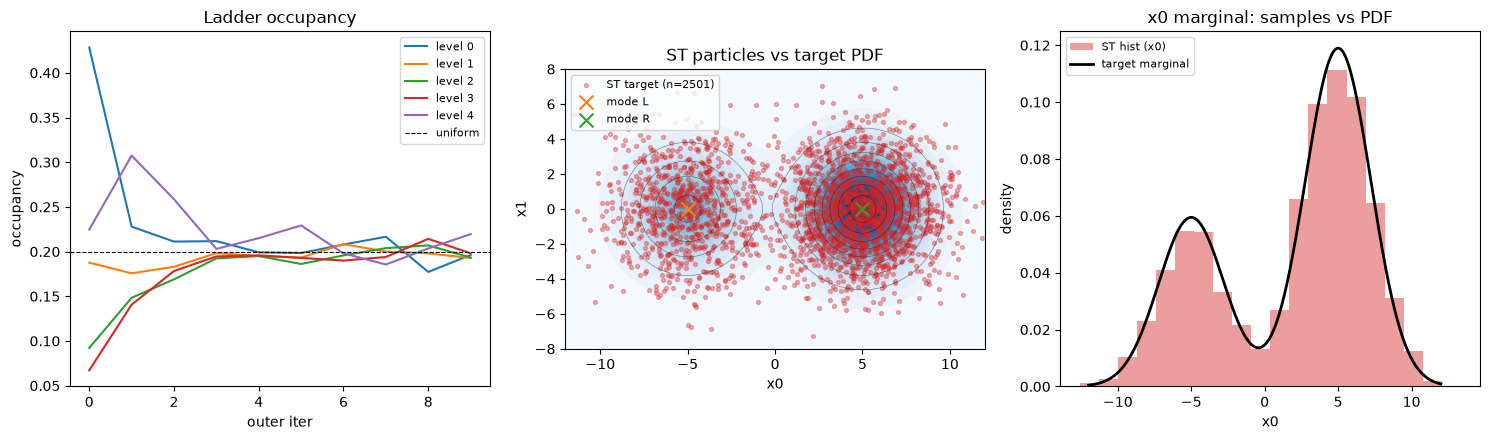

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1) Occupancy over outer iterations (from pipe.run(..., history=...))
occ = jnp.stack([h["occupancy"] for h in history])
for i in range(n_levels):
    axes[0].plot(occ[:, i], label=f"level {i}")
axes[0].axhline(1 / n_levels, color="k", ls="--", lw=0.8, label="uniform")
axes[0].set_xlabel("outer iter")
axes[0].set_ylabel("occupancy")
axes[0].set_title("Ladder occupancy")
axes[0].legend(fontsize=8)

# Target PDF on a grid
x_min, x_max = -12.0, 12.0
y_min, y_max = -8.0, 8.0
gs = 200
xx, yy = jnp.meshgrid(
    jnp.linspace(x_min, x_max, gs),
    jnp.linspace(y_min, y_max, gs),
)
grid = jnp.stack([xx.ravel(), yy.ravel()], axis=-1)
pdf = target_pdf(grid).reshape(xx.shape)

# 2) Target PDF contours + pooled ST particles from parallel replica collect
axes[1].contourf(xx, yy, pdf, levels=30, cmap="Blues")
axes[1].contour(xx, yy, pdf, levels=8, colors="k", linewidths=0.4, alpha=0.5)
if at_target.shape[0] > 0:
    axes[1].scatter(
        at_target[:, 0],
        at_target[:, 1],
        s=8,
        c="C3",
        alpha=0.35,
        label=f"ST target (n={at_target.shape[0]})",
    )
axes[1].scatter(*MEAN_LEFT, c="C1", marker="x", s=100, zorder=5, label="mode L")
axes[1].scatter(*MEAN_RIGHT, c="C2", marker="x", s=100, zorder=5, label="mode R")
axes[1].set_xlim(x_min, x_max)
axes[1].set_ylim(y_min, y_max)
axes[1].set_xlabel("x0")
axes[1].set_ylabel("x1")
axes[1].set_title("ST particles vs target PDF")
axes[1].legend(fontsize=8, loc="upper left")
axes[1].set_aspect("equal", adjustable="box")

# 3) 1D marginal on x0: histogram vs target marginal PDF
x_line = jnp.linspace(x_min, x_max, 400)
marginal = marginal_x0_pdf(x_line)
if at_target.shape[0] > 0:
    axes[2].hist(
        at_target[:, 0],
        bins='auto',
        density=True,
        color="C3",
        alpha=0.45,
        label="ST hist (x0)",
    )
axes[2].plot(x_line, marginal, "k-", lw=2, label="target marginal")
axes[2].set_xlabel("x0")
axes[2].set_ylabel("density")
axes[2].set_title("x0 marginal: samples vs PDF")
axes[2].legend(fontsize=8)

fig.tight_layout()
plt.show()